In [1]:
# Step 1: Import Libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import pickle

Images shape: (1797, 8, 8)
Labels shape: (1797,)


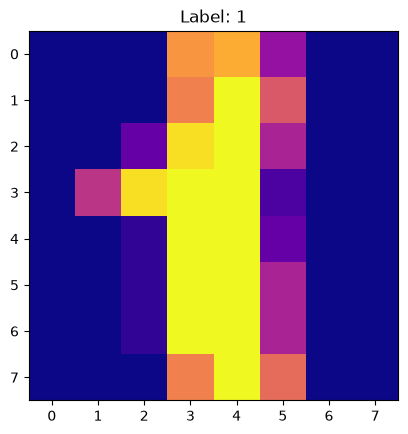

In [25]:
# Step 2: Load Digits Dataset
digits = load_digits()

print("Images shape:", digits.images.shape)   # (1797, 8, 8)
print("Labels shape:", digits.target.shape)   # (1797,)

# Display second image
plt.imshow(digits.images[1], cmap='plasma')
plt.title(f"Label: {digits.target[1]}")
plt.show()

In [17]:
f"{digits.images}"

'[[[ 0.  0.  5. ...  1.  0.  0.]\n  [ 0.  0. 13. ... 15.  5.  0.]\n  [ 0.  3. 15. ... 11.  8.  0.]\n  ...\n  [ 0.  4. 11. ... 12.  7.  0.]\n  [ 0.  2. 14. ... 12.  0.  0.]\n  [ 0.  0.  6. ...  0.  0.  0.]]\n\n [[ 0.  0.  0. ...  5.  0.  0.]\n  [ 0.  0.  0. ...  9.  0.  0.]\n  [ 0.  0.  3. ...  6.  0.  0.]\n  ...\n  [ 0.  0.  1. ...  6.  0.  0.]\n  [ 0.  0.  1. ...  6.  0.  0.]\n  [ 0.  0.  0. ... 10.  0.  0.]]\n\n [[ 0.  0.  0. ... 12.  0.  0.]\n  [ 0.  0.  3. ... 14.  0.  0.]\n  [ 0.  0.  8. ... 16.  0.  0.]\n  ...\n  [ 0.  9. 16. ...  0.  0.  0.]\n  [ 0.  3. 13. ... 11.  5.  0.]\n  [ 0.  0.  0. ... 16.  9.  0.]]\n\n ...\n\n [[ 0.  0.  1. ...  1.  0.  0.]\n  [ 0.  0. 13. ...  2.  1.  0.]\n  [ 0.  0. 16. ... 16.  5.  0.]\n  ...\n  [ 0.  0. 16. ... 15.  0.  0.]\n  [ 0.  0. 15. ... 16.  0.  0.]\n  [ 0.  0.  2. ...  6.  0.  0.]]\n\n [[ 0.  0.  2. ...  0.  0.  0.]\n  [ 0.  0. 14. ... 15.  1.  0.]\n  [ 0.  4. 16. ... 16.  7.  0.]\n  ...\n  [ 0.  0.  0. ... 16.  2.  0.]\n  [ 0.  0.  4. ... 1

In [3]:
# Step 3: Prepare Data
# Flatten 8x8 images into 64 features
X = digits.images.reshape((len(digits.images), -1))
y = digits.target

print("Feature shape:", X.shape)  # (1797, 64)

Feature shape: (1797, 64)


In [4]:
# Step 4: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
# Step 5: Train SVM Classifier
svm = SVC(kernel="linear", C=1)
svm.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [6]:
# Step 6: Evaluate Model
y_pred = svm.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9777777777777777
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.97      1.00      0.98        28
           2       1.00      1.00      1.00        33
           3       0.97      0.94      0.96        34
           4       0.98      0.98      0.98        46
           5       0.96      1.00      0.98        47
           6       1.00      1.00      1.00        35
           7       0.97      0.97      0.97        34
           8       1.00      0.97      0.98        30
           9       0.95      0.93      0.94        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [7]:
# Step 7: Save Model with Pickle
with open("svm_rps_model.pkl", "wb") as f:
    pickle.dump(svm, f)

print("✅ Model saved as svm_rps_model.pkl")

✅ Model saved as svm_rps_model.pkl


In [8]:
# Step 8: Load Model Back & Test Prediction
with open("svm_rps_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

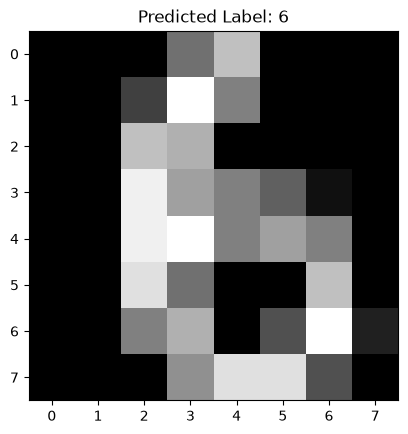

In [22]:
sample = X_test[0].reshape(1, -1)
prediction = loaded_model.predict(sample)[0]

plt.imshow(X_test[0].reshape(8, 8), cmap='gray')
plt.title(f"Predicted Label: {prediction}")
plt.show()